# Gradients, depth and wide registers

Training a variational circuit or a quantum machine-learning model asks a simulator
the same kind of question over and over: expectation values of several observables,
for every data example, and for every shifted circuit a gradient needs. LazyQC's
planner is built for these batches. It looks for three kinds of avoidable work:

- **irrelevance**: gates outside an observable's causal cone cannot change its value;
- **redundancy**: different outputs, examples and shifted circuits often reduce to the
  *same* cone circuit, which only needs to be simulated once;
- **repetition**: the circuit's shape stays the same across examples, shifts and
  training steps, so the analysis that finds the first two can be shared too.

We see all three on a parameter-shift gradient, then look at the two properties that
decide whether any of it helps: how deep the circuit is, and how wide.

In [1]:
import os

# One native thread per library, so timings compare algorithms rather than core counts.
# This has to happen before Qulacs is imported.
for key in ("QULACS_NUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import math
import random

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from lazyqc import NoFeasiblePlan, Parameter, Program, plan_all
from nbtools import table, timed


def tidy(ax):
    """Light styling shared by the charts below."""
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

## The ansatz: a hardware-efficient brickwork

Every layer applies an $RY$ rotation to each qubit and then CX gates on alternating
neighbouring pairs, so the entangling pattern shifts by one wire from layer to layer.
Each rotation gets its own parameter.

In [2]:
def brickwork(n, depth, angles=None):
    """`depth` layers of RY on every wire followed by CX on alternating neighbouring pairs."""
    program, k = Program(n), 0
    for layer in range(depth):
        for q in range(n):
            program = program.ry(q, angles[k] if angles else 0.1 + 0.01 * k)
            k += 1
        for q in range(layer % 2, n - 1, 2):
            program = program.cx(q, q + 1)
    return program

## 1. A parameter-shift Jacobian

For a rotation $R_P(\theta)=\exp(-i\theta P/2)$ the parameter-shift rule gives an exact
derivative from two shifted circuits:

$$\frac{\partial\langle O\rangle}{\partial\theta_i}
  = \frac{\langle O\rangle_{\theta_i+\pi/2} - \langle O\rangle_{\theta_i-\pi/2}}{2}.$$

The full Jacobian of $K$ outputs with respect to $P$ parameters therefore needs the
base circuit and $2P$ shifted ones, each with all $K$ outputs: $(2P+1)K$ expectation
values. We take 12 qubits, 3 layers and $\langle Z_k\rangle$ on every wire.

In [3]:
n, depth = 12, 3
thetas = [Parameter(f"theta_{i}") for i in range(n * depth)]
ansatz = brickwork(n, depth, thetas)  # angles left open
rng = random.Random(3)
point = {t.name: rng.uniform(-1, 1) for t in thetas}

programs = [ansatz.bind(**point)]
for t in thetas:
    for shift in (math.pi / 2, -math.pi / 2):
        programs.append(ansatz.bind(**{**point, t.name: point[t.name] + shift}))
requests = [program.expectation({k: "Z"}) for program in programs for k in range(n)]
P, K = len(thetas), n
print(f"P = {P} parameters and K = {K} outputs: {len(programs)} programs, {len(requests)} requests")

P = 36 parameters and K = 12 outputs: 73 programs, 876 requests


The planner receives all of them as one batch. Dense simulation, for comparison,
prepares one full 12-qubit state per program:

In [4]:
plan, plan_ms = timed(lambda: plan_all(requests), repeats=3)
result, collect_ms = timed(plan.collect, repeats=3)
dense, dense_ms = timed(lambda: plan_all(requests, strategy="full").collect(), repeats=3)
widths = [g["state_qubits"] for g in plan.explain()["groups"]]
table(
    [
        ("dense: one full state per program", len(programs), n, dense_ms),
        ("LazyQC: grouped cones", len(widths), max(widths), plan_ms + collect_ms),
    ],
    ["plan", "simulations", "widest state (qubits)", "total time (ms)"],
)
print(f"planning took {plan_ms:.1f} ms of LazyQC's total")

| plan | simulations | widest state (qubits) | total time (ms) |
|---|---|---|---|
| dense: one full state per program | 73 | 12 | 60.7 |
| LazyQC: grouped cones | 138 | 6 | 22.3 |

planning took 11.6 ms of LazyQC's total


Hundreds of requests became a much smaller number of distinct simulations. Two effects
stack: each output only needs its cone, and a circuit whose shifted rotation lies
outside an output's cone has *exactly the same* cone circuit as the unshifted one, so
the two share a task.

## Structural zeros

That sharing has a striking consequence. If $\theta_i$ lies outside the cone of $Z_k$,
both shifted circuits give $Z_k$ the same cone circuit, the planner simulates it once,
and the derivative comes out as exactly `0.0` with no special handling. The zero
pattern of the Jacobian is a picture of the light cones:

LazyQC: 305 of 432 entries exactly zero (71%), 22 more are rounding noise
dense:  19 entries exactly zero, 308 more are rounding noise
max difference between the two Jacobians: 2.4e-15


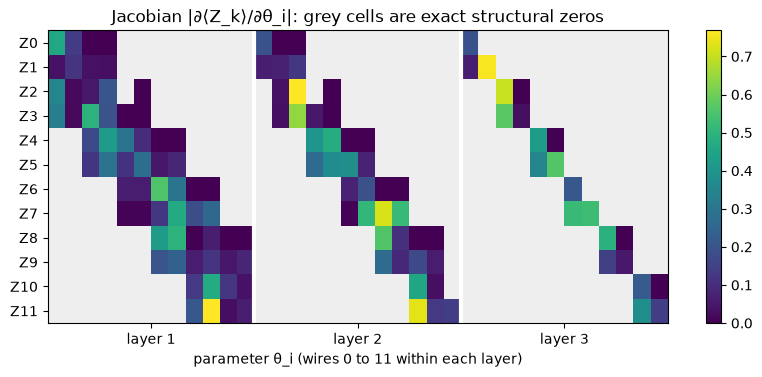

In [5]:
def jacobian(values):
    """Parameter-shift Jacobian from the values of the base and 2P shifted programs."""
    return np.array([[(values[(1 + 2 * i) * K + k] - values[(2 + 2 * i) * K + k]) / 2 for i in range(P)]
                     for k in range(K)])


J, J_dense = jacobian(result.values), jacobian(dense.values)
def noise(M):
    """Entries that are not exactly zero but below 1e-12: rounding noise around a true zero."""
    return int(((M != 0) & (np.abs(M) < 1e-12)).sum())


zeros = int((J == 0.0).sum())
print(f"LazyQC: {zeros} of {P * K} entries exactly zero ({zeros / (P * K):.0%}), {noise(J)} more are rounding noise")
print(f"dense:  {int((J_dense == 0.0).sum())} entries exactly zero, {noise(J_dense)} more are rounding noise")
print(f"max difference between the two Jacobians: {np.abs(J - J_dense).max():.1e}")

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("#EEEEEE")
fig, ax = plt.subplots(figsize=(10, 3.8))
image = ax.imshow(np.ma.masked_equal(np.abs(J), 0.0), cmap=cmap, aspect="auto")
for layer in range(1, depth):
    ax.axvline(layer * n - 0.5, color="white", linewidth=3)
ax.set_yticks(range(K), [f"Z{k}" for k in range(K)])
ax.set_xticks([layer * n + n / 2 - 0.5 for layer in range(depth)], [f"layer {layer + 1}" for layer in range(depth)])
ax.set_xlabel("parameter θ_i (wires 0 to 11 within each layer)")
ax.set_title("Jacobian |∂⟨Z_k⟩/∂θ_i|: grey cells are exact structural zeros")
fig.colorbar(image, ax=ax)
plt.show()

Both Jacobians agree to about $10^{-15}$ and vanish in the same places, but they
report it differently. LazyQC returns most vanishing derivatives as exact zeros. The
few that come out as rounding noise are the conservative-cone cases: the support-based
scan keeps a gate that cannot actually change the output (notebook 05 shows one), so
the two shifted circuits differ inside the cone and are simulated separately. Dense
simulation returns almost all of them as rounding noise, because every shifted circuit
is a different full state.

Two caveats from the paper:

- Structural zeros rely on every rotation having its own parameter. If one parameter
  is shared by many rotations, a derivative is zero only when *none* of its
  occurrences lies in the cone, which is much rarer.
- A full Jacobian suits multi-output sensitivity or kernel methods. An ordinary
  training step only needs the gradient of a scalar loss, which adjoint
  differentiation gets in about two passes over the state; at small widths that
  beats the planner.

## 2. Repetition: analysing shape, not angles

Cone membership depends only on which wires each gate touches, never on its angle.
All programs in this batch share one shape, so the planner computes the cones once
per shape and observable support (12 times here, not once per request), and each
request then only gathers its own angles. Planning time per request stays small as the
batch grows:

In [6]:
rows = []
for count in (1, 9, 25, len(programs)):
    batch = [program.expectation({k: "Z"}) for program in programs[:count] for k in range(K)]
    _, ms = timed(lambda: plan_all(batch), repeats=3)
    rows.append((count, len(batch), ms, 1e3 * ms / len(batch)))
table(rows, ["programs", "requests", "planning (ms)", "per request (µs)"])

| programs | requests | planning (ms) | per request (µs) |
|---|---|---|---|
| 1 | 12 | 0.400 | 33.4 |
| 9 | 108 | 1.70 | 15.7 |
| 25 | 300 | 3.56 | 11.9 |
| 73 | 876 | 10.7 | 12.3 |

For comparison, the paper ran Qiskit's commutation-aware `LightCone` pass separately on
every request of a 3,220-request Jacobian: 7.3 s of analysis, against 28.6 ms for
LazyQC's structure-keyed analysis of the same batch.

## 3. Depth decides how much there is to avoid

Each brickwork layer widens a cone by one wire on each side, until it covers the whole
register; from then on there is nothing left to remove. We follow 16 qubits from depth
1 to 10, with $\langle Z_k\rangle$ on every wire. To measure *work* we count
amplitude-gate updates: a gate on a $w$-qubit state touches $2^w$ amplitudes, so dense
simulation does $G\cdot 2^{16}$ of them and a cone plan $\sum_g |C_g|\,2^{w_g}$.

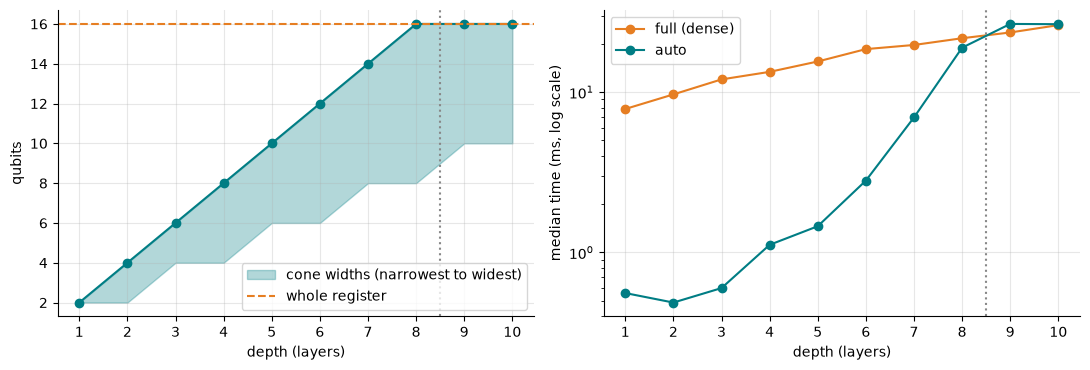

auto keeps the dense plan from depth 9 on


| depth | cone widths | work avoided (×) | auto picks | auto (ms) | full (ms) |
|---|---|---|---|---|---|
| 1 | 2-2 | 16384 | grouped | 0.558 | 7.85 |
| 2 | 2-4 | 2962 | grouped | 0.486 | 9.68 |
| 3 | 4-6 | 635 | grouped | 0.599 | 12.0 |
| 4 | 4-8 | 147 | grouped | 1.12 | 13.4 |
| 5 | 6-10 | 37.1 | grouped | 1.46 | 15.5 |
| 6 | 6-12 | 10.0 | grouped | 2.80 | 18.5 |
| 7 | 8-14 | 3.03 | grouped | 6.95 | 19.7 |
| 8 | 8-16 | 1.08 | grouped | 18.9 | 21.7 |
| 9 | 10-16 | 0.633 | full | 26.6 | 23.6 |
| 10 | 10-16 | 0.439 | full | 26.5 | 26.2 |

In [7]:
n_sweep = 16
sweep = []
for d in range(1, 11):
    program = brickwork(n_sweep, d)
    batch = [program.expectation({k: "Z"}) for k in range(n_sweep)]
    cones = plan_all(batch, strategy="grouped").explain()["groups"]
    dense_work = len(program.resolved_operations()) * 2**n_sweep
    cone_work = sum(g["gate_count"] * 2 ** g["state_qubits"] for g in cones)
    picks = plan_all(batch).explain()["selected_candidate"]
    _, auto_ms = timed(lambda: plan_all(batch).collect(), repeats=3)
    _, full_ms = timed(lambda: plan_all(batch, strategy="full").collect(), repeats=3)
    widths = [g["state_qubits"] for g in cones]
    sweep.append((d, min(widths), max(widths), dense_work / cone_work, picks, auto_ms, full_ms))

depths = [row[0] for row in sweep]
switch = next((row[0] for row in sweep if row[4] == "full"), None)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
left.fill_between(depths, [row[1] for row in sweep], [row[2] for row in sweep], color="#007D84", alpha=0.3,
                  label="cone widths (narrowest to widest)")
left.plot(depths, [row[2] for row in sweep], color="#007D84", marker="o")
left.axhline(n_sweep, color="#E67E22", linestyle="--", label="whole register")
left.set_xlabel("depth (layers)")
left.set_ylabel("qubits")
left.legend(loc="lower right")
right.plot(depths, [row[6] for row in sweep], color="#E67E22", marker="o", label="full (dense)")
right.plot(depths, [row[5] for row in sweep], color="#007D84", marker="o", label="auto")
right.set_yscale("log")
right.set_xlabel("depth (layers)")
right.set_ylabel("median time (ms, log scale)")
right.legend()
for ax in (left, right):
    ax.set_xticks(depths)
    if switch:
        ax.axvline(switch - 0.5, color="#888888", linestyle=":")
    tidy(ax)
fig.tight_layout()
plt.show()
print(f"auto keeps the dense plan from depth {switch} on" if switch else "auto never chose the dense plan")
table(
    [(d, f"{lo}-{hi}", ratio, picks, auto_ms, full_ms) for d, lo, hi, ratio, picks, auto_ms, full_ms in sweep],
    ["depth", "cone widths", "work avoided (×)", "auto picks", "auto (ms)", "full (ms)"],
)

The work avoided drops by a factor of three to five with every layer, until the cones
cover the register. Past that point a cone plan would do *more* work than the dense one
(ratios below 1), because several outputs would each need a nearly full-width task.
From that depth on `auto` keeps the dense plan and pays only a small planning
overhead. These are the paper's regimes
in one picture: **narrow cones**, where planning wins by an exponential margin;
**saturated cones**, where the right move is to hand the dense work to the fastest
device; and in between, a boundary that depends on depth and connectivity, not on the
register size.

## 4. Wider than any statevector

Dense simulation needs $2^n$ amplitudes of 16 bytes each, so 28 qubits already take
4 GiB, and 128 qubits would need about $5\times10^{39}$ bytes. The cones of a shallow
local circuit, however, do not grow with the register. Here are 128-qubit brickworks
at depths 4, 6 and 8, with $\langle Z_k\rangle$ on all 128 wires:

In [8]:
rows = []
for d in (4, 6, 8):
    program = brickwork(128, d)
    batch = [program.expectation({k: "Z"}) for k in range(128)]
    wide_plan, plan_ms = timed(lambda: plan_all(batch), repeats=1)
    _, collect_ms = timed(wide_plan.collect, repeats=1)
    info = wide_plan.explain()
    rows.append((d, len(batch), len(info["groups"]), info["max_state_qubits"], plan_ms, collect_ms))
table(rows, ["depth", "outputs", "tasks", "widest task (qubits)", "planning (ms)", "collection (ms)"])

full = next(alt for alt in info["alternatives"] if alt["candidate"] == "full")
print("full plan rejected:", full["rejection"])

| depth | outputs | tasks | widest task (qubits) | planning (ms) | collection (ms) |
|---|---|---|---|---|---|
| 4 | 128 | 65 | 8 | 12.5 | 4.52 |
| 6 | 128 | 65 | 12 | 23.1 | 32.4 |
| 8 | 128 | 65 | 16 | 27.1 | 624 |

full plan rejected: width 128 exceeds 24; state payload 5444517870735015415413993718908291383296 exceeds 268435456 bytes


The cost follows the widest cone, not the register: every two layers add four qubits to
the widest task and multiply the collection time accordingly.

This is *not* dense 128-qubit simulation: every task is a small statevector. A shared
exact matrix-product state (MPS) is a much stronger competitor than independent dense
runs. In the paper's measurements at 128 qubits it was 7 to 17 times slower than
LazyQC on local families like this one, and it succeeds where cones saturate. LazyQC
refuses those cases instead of attempting a $2^{128}$-amplitude state:

In [9]:
deep = brickwork(128, 14)
try:
    plan_all([deep.expectation({k: "Z"}) for k in range(128)])
except NoFeasiblePlan as error:
    print("NoFeasiblePlan:", error)

NoFeasiblePlan: full: width 128 exceeds 24; state payload 5444517870735015415413993718908291383296 exceeds 268435456 bytes; separate: width 28 exceeds 24; state payload 4294967296 exceeds 268435456 bytes; grouped: width 28 exceeds 24; state payload 4294967296 exceeds 268435456 bytes


## 5. Planning and faster hardware compose

A GPU makes every amplitude update faster; the planner removes updates. They attack
different factors of the same cost, so they combine. After planning, tasks can differ
a lot in width: a narrow task takes microseconds on a CPU, less than the fixed cost of
launching anything on a GPU, while a wide task benefits from the GPU's memory
bandwidth. `collect` therefore accepts a second backend and a width threshold: tasks
with at least `wide_from` qubits run on `wide_backend` and the rest stay on the CPU.

Here is how the work of a 48-qubit, depth-8 brickwork spreads across task widths. The
threshold of 14 qubits is the per-task CPU/GPU crossover the paper measured on its
laptop:

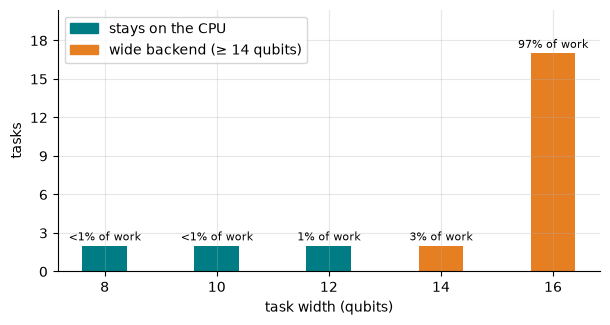

19 of 25 tasks have at least 14 qubits and carry 99% of the amplitude updates


In [10]:
program = brickwork(48, 8)
batch = [program.expectation({k: "Z"}) for k in range(48)]
plan48 = plan_all(batch)
groups = plan48.explain()["groups"]
wide_from = 14

widths = sorted({g["state_qubits"] for g in groups})
count = {w: sum(g["state_qubits"] == w for g in groups) for w in widths}
work = {w: sum(g["gate_count"] * 2**w for g in groups if g["state_qubits"] == w) for w in widths}
total = sum(work.values())

fig, ax = plt.subplots(figsize=(7, 3.4))
bars = ax.bar(widths, [count[w] for w in widths], color=["#E67E22" if w >= wide_from else "#007D84" for w in widths])
shares = [work[w] / total for w in widths]
ax.bar_label(bars, labels=[f"{s:.0%} of work" if s >= 0.005 else "<1% of work" for s in shares], padding=2, fontsize=8)
ax.set_xticks(widths)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("task width (qubits)")
ax.set_ylabel("tasks")
ax.margins(y=0.2)
ax.legend(handles=[Patch(color="#007D84", label="stays on the CPU"),
                   Patch(color="#E67E22", label=f"wide backend (≥ {wide_from} qubits)")], loc="upper left")
tidy(ax)
plt.show()

wide_tasks = sum(count[w] for w in widths if w >= wide_from)
share = sum(work[w] for w in widths if w >= wide_from) / total
print(f"{wide_tasks} of {len(groups)} tasks have at least {wide_from} qubits and carry {share:.0%} of the amplitude updates")

If a GPU build of Qiskit Aer is installed (`qiskit-aer-gpu` in place of
`qiskit-aer`), the next cell times the plan with and without placement:

In [11]:
try:
    from qiskit_aer import AerSimulator

    has_gpu = "GPU" in AerSimulator().available_devices()
except ImportError:
    has_gpu = False

if has_gpu:
    from lazyqc.backends.aer import AerBackend

    gpu = AerBackend(device="GPU")
    plan48.collect(wide_backend=gpu, wide_from=wide_from)  # warm up the device
    cpu_result, cpu_ms = timed(plan48.collect, repeats=3)
    placed, placed_ms = timed(lambda: plan48.collect(wide_backend=gpu, wide_from=wide_from), repeats=3)
    difference = max(abs(a - b) for a, b in zip(cpu_result.values, placed.values))
    print(f"CPU only: {cpu_ms:.0f} ms; wide tasks on the GPU: {placed_ms:.0f} ms (max difference {difference:.1e})")
else:
    print("No GPU build of Qiskit Aer in this environment, so the timing is skipped.")

No GPU build of Qiskit Aer in this environment, so the timing is skipped.


On a similar 48-qubit depth-8 family on its laptop GPU, the paper measured 1.48 s for
CPU-only collection and 171 ms with tasks of at least 14 qubits on the GPU, with the
same plan. Sending *every* task to the GPU is a mistake below about 20 qubits: each
narrow task pays the GPU's fixed launch cost, which made it 0.19 to 0.39 times as
fast as direct execution at 12 and 16 qubits. Placement happens after selection,
though: the work score assumes a statevector and does not know which devices exist,
so choosing plan and device together is still open.

## What to take away

- In gradient and QML batches the savings come from three places: cones
  (irrelevance), identical cone circuits across outputs, examples and shifts
  (redundancy), and analysis keyed on circuit shape (repetition).
- Structural zeros fall out of exact sharing: a derivative whose parameter lies
  outside the cone is computed as exactly zero.
- Depth decides. Each layer widens the cones, and once they cover the register there
  is nothing to avoid, so `auto` keeps the dense plan.
- Logical width alone does not matter; cone width does. LazyQC handles 128 logical
  qubits with narrow cones and refuses saturated ones, where tensor networks such as
  MPS are the better tool.
- Planning decides *how much* to simulate and hardware decides *how fast*. Placing
  only the wide tasks on a GPU combines both.

## Try it yourself

- Tie the parameters: give all rotations of a layer one `Parameter`, rebuild the
  shifted programs and count the structural zeros again.
- Replace the brickwork with a CX ladder (`cx(q, q + 1)` for every `q` in every
  layer) and watch how quickly the cones saturate.